# Literal three-spin Lindblad workload

This fixed study uses **n=3, r=134, local Z0 and 15,756 complete trials** with $t=1$, $J=0.6$, $h_x=0.35$, rates 0.8/0.5/0.5 and +i/+/+ input. Every trial retains all 673 source resets, every Hamiltonian/damping component and six final readouts. All three system outcomes stay correlated; the bounded scalar score depends only on bit0. Environment readouts are ignored and reset histories are unobserved.

The notebook loads the saved actual Clifford+T and conditional physical records, verifies their identities, and runs **one fresh literal six-wire density check** plus independent gate/GKSL references. It starts no new native synthesis or QDK estimate. The complete trial ensemble and hardware schedule remain unexecuted. The earlier n2 bundle stays preserved; n4 physical work remains unimplemented and its family allocation unused.

In [1]:
from pathlib import Path
from fractions import Fraction
from dataclasses import asdict
import hashlib, importlib.metadata, json, math, platform, re, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display
from qiskit import qasm3

root=Path.cwd()
local=(root/"lindblad_three_physical.py").is_file()
if not local and root.name=="notebooks" and (root.parent/"src/openquantum/simulation/lindblad_three_physical.py").is_file():
    root=root.parent
if not local and (root/"src/openquantum/simulation/lindblad_three_physical.py").is_file():
    sys.path.insert(0,str(root/"src"))
    from openquantum.simulation import lindblad_three_physical as lp
    from openquantum.simulation import bounded_density_instrument as di
    from openquantum.simulation import lindblad_workload as lw
    from openquantum import instrument_resources as ir
    asset_dir=root/"assets/generated/simulation/lindblad-three"
else:
    sys.path.insert(0,str(root))
    import lindblad_three_physical as lp
    import bounded_density_instrument as di
    import lindblad_workload as lw
    import instrument_resources as ir
    asset_dir=root
get_ipython().run_line_magic("matplotlib","inline")
manifest=json.loads((asset_dir/"manifest.json").read_text())
results=json.loads((asset_dir/"results.json").read_text())
assert platform.python_version()==manifest["python"], "Use the recorded locked Python runtime."
prepared=results["prepared"]
assert prepared is not None, "The saved preparation stage must complete before this notebook runs."
profiles=results["physical_profiles"]
assert len(profiles)==2
assert {r["profile"]["physical_error_rate"] for r in profiles}=={1e-3,1e-4}
family=results["family"]
family_records=list(family.values()) if isinstance(family,dict) else family
for name,expected in manifest["artifacts_sha256"].items():
    assert hashlib.sha256((asset_dir/name).read_bytes()).hexdigest()==expected, name
for name,expected in manifest["source_sha256"].items():
    assert hashlib.sha256((asset_dir/name).read_bytes()).hexdigest()==expected, name
for module in (lp,di,lw,ir):
    path=Path(module.__file__)
    assert hashlib.sha256(path.read_bytes()).hexdigest()==manifest["source_sha256"][path.name], path.name
for name,expected in manifest["packages"].items():
    assert importlib.metadata.version(name)==expected, name
limits=ir.InstrumentLimits(**prepared["limits"])
checker_limits=di.DenseInstrumentLimits(**prepared["checker_limits"])
assert limits.max_qubits==checker_limits.max_qubits==6
assert limits.source_operations==checker_limits.source_operations==20000
assert limits.synthesized_operations==limits.validation_operations==checker_limits.validation_operations==1000000
assert di.DenseInstrumentLimits().max_qubits==5
assert di.DenseInstrumentLimits().source_operations==10000
assert di.DenseInstrumentLimits().validation_operations==100000
assert checker_limits.matrix_cache_bytes==1024**2

def table(frame):
    display(frame.style.hide(axis="index").format(precision=9,na_rep="—"))
def fraction(record):
    return Fraction(record["numerator"],record["denominator"])
def density(record):
    return np.array(record["real"])+1j*np.array(record["imag"])
def point(report):
    values=report.get("pareto_points",[])
    return min(values,key=lambda p:(p["peak_physical_qubits"],p["worst_case_runtime_all_attempts_ns"])) if values else None
print("Saved artifact, copied-source and package identities verified; six-wire validation is an explicit opt-in.")

Saved artifact, copied-source and package identities verified; six-wire validation is an explicit opt-in.


## Fresh source, gate-derived reference and GKSL target

The checker propagates the full $64\times64$ density operator through the complete source. Reset is the unobserved sum of two Kraus terms; it does not create a classical output. Before the first system measurement, the checker retains the full $8\times8$ reduced system state and all eight final system probabilities. Output bit order is q2q1q0 and the score table alternates +1/−1 by bit0.

An independent contraction of matrices from the actual ZZ/RX and environment-dilation gates checks the literal schedule. A separately assembled full GKSL exponential supplies the target. Dense matrices are classical references, never quantum circuit gates. The saved routed/Clifford+T checks are loaded rather than rerun; density agreement does not certify the separate representation or SDK reserves.

stage,Z0
GKSL reference,0.791050939
Fresh literal source,0.791052626
Saved routed,0.791052626
Saved actual Clifford+T,0.791052310


comparison,trace_norm
Fresh source vs gate-derived state,0.000000000
Fresh source vs full GKSL state,0.000013904


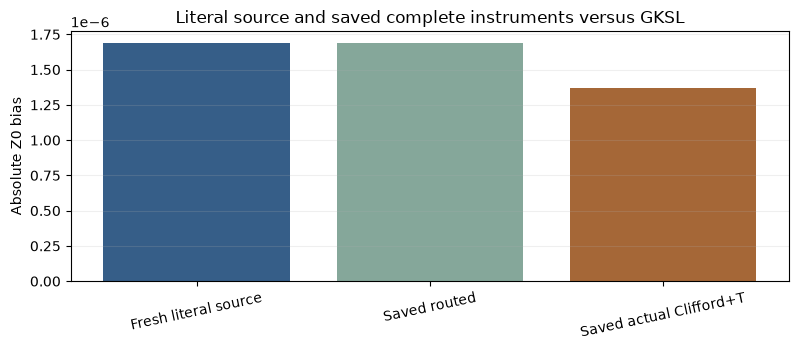

In [2]:
task=lp.source_task()
assert asdict(task)=={"n_system":3,"time":1.0,"J":0.6,"hx":0.35,"rate0":0.8,"other_rate":0.5}
assert lw.select_steps(task)==134
assert lw.output_contract()["complete_trials_per_case"]==15756
source=lp.build_source(task)
di.validate_density_source(source,limits=checker_limits)
assert source.num_qubits==source.num_clbits==6 and len(source.data)==4435
assert source.count_ops()["reset"]==673 and source.count_ops()["measure"]==6
source_readouts=[(source.find_bit(item.clbits[0]).index,source.find_bit(item.qubits[0]).index)
                 for item in source.data if item.operation.name=="measure"]
assert source_readouts==[(q,q) for q in range(6)]
assert hashlib.sha256(qasm3.dumps(source).encode()).hexdigest()==prepared["qasm_sha256"]["source-trial.qasm"]
for name,expected in prepared["qasm_sha256"].items():
    raw=(asset_dir/name).read_bytes()
    assert hashlib.sha256(raw).hexdigest()==expected, name
    # Independent fixed-export check: six distinct final quantum targets,
    # including all ignored environment readouts, map to six distinct bits.
    readouts=re.findall(r"^\s*c\[(\d+)\]\s*=\s*measure\s+(?:q\[(\d+)\]|\$(\d+));\s*$",raw.decode(),re.MULTILINE)
    assert len(readouts)==6, name
    mapping={int(bit):int(register_wire or physical_wire) for bit,register_wire,physical_wire in readouts}
    assert set(mapping)==set(mapping.values())==set(range(6)), name
    stage={"source-trial.qasm":"source_instrument_check", "routed-rotation-trial.qasm":"routed_instrument_check",
           "clifford-t-trial.qasm":"clifford_t_instrument_check"}[name]
    assert [mapping[q] for q in range(3)]==prepared[stage]["outcome_wires"], name
fresh=di.simulate_density_trial(source,(0,1,2),lp.score_values(),{},limits=checker_limits)
rho=fresh["reduced_before_output"]
reference=lw.reference_density(task)
gate_reference=lw.gate_density(task,134)
observable=lw.on_wire(lw.Z,0,3)
exact=float(np.trace(observable@reference).real)
guard=lp.NUMERICAL_CHECK_GUARD
assert rho.shape==(8,8) and fresh["joint_probabilities"].shape==(8,)
assert abs(fresh["acceptance_probability"]-1)<guard
assert abs(np.trace(rho)-1)<guard and np.linalg.eigvalsh(rho).min()>-guard
assert np.linalg.norm(rho-gate_reference,ord="nuc")<guard
assert np.linalg.norm(rho-reference,ord="nuc")<=float(lw.uniform_split_bound(task,134))+guard
assert abs(fresh["mean"]-prepared["source_instrument_check"]["mean"])<guard
assert np.linalg.norm(rho-density(prepared["source_instrument_check"]["reduced_before_output"]),ord="nuc")<guard
assert np.max(np.abs(fresh["joint_probabilities"]-prepared["source_instrument_check"]["joint_probabilities"]))<guard
assert abs(float(np.trace(observable@gate_reference).real)-fresh["mean"])<guard
assert abs(exact-prepared["independent_reference"]["exact_GKSL_Z0"])<guard
sim=fresh["simulation"]
assert sim["density_shape"]==[64,64] and sim["density_state_bytes"]==65536
assert sim["reset_history_measured_outputs"] is False
assert sim["reset_history_classical_bits_created"]==0 and sim["trajectory_branch_pruning"] is False
assert sim["explicit_instrument_counts"]=={"reset":673,"measure":6}
assert sim["peak_matrix_cache_bytes"]<=sim["matrix_cache_bytes_limit"]==1024**2
answers=[{"stage":"GKSL reference","Z0":exact},
         {"stage":"Fresh literal source","Z0":fresh["mean"]},
         {"stage":"Saved routed","Z0":prepared["routed_instrument_check"]["mean"]},
         {"stage":"Saved actual Clifford+T","Z0":prepared["clifford_t_instrument_check"]["mean"]}]
table(pd.DataFrame(answers))
table(pd.DataFrame([{"comparison":"Fresh source vs gate-derived state","trace_norm":np.linalg.norm(rho-gate_reference,ord="nuc")},
                    {"comparison":"Fresh source vs full GKSL state","trace_norm":np.linalg.norm(rho-reference,ord="nuc")}]))
fig,ax=plt.subplots(figsize=(8,3.6))
ax.bar([r["stage"] for r in answers[1:]],[abs(r["Z0"]-exact) for r in answers[1:]],color=["#365e88","#85a79a","#a56737"])
ax.set(ylabel="Absolute Z0 bias",title="Literal source and saved complete instruments versus GKSL")
ax.ticklabel_format(axis="y",style="sci",scilimits=(-3,3))
ax.tick_params(axis="x",rotation=12)
ax.grid(axis="y",alpha=.2)
fig.tight_layout()
plt.show()

## Correlations are part of the checked channel

The local Z0 mean alone cannot validate three interacting systems. The following diagnostic forms a **classical product of the source's single-system marginals**. That product has the same local Z0 mean but different ZZ witnesses, joint probabilities and full state. It is not a replacement quantum circuit or a pruning rule.

The full source/routed/Clifford+T $8\times8$ states and eight-outcome laws remain in the saved checks. The fresh source is compared with those records. No reset histories are mistaken for measured environment outcomes.

observable,literal_source,product_of_source_marginals,GKSL_reference
Z0,0.791052626,0.791052626,0.791050939
Z0 Z1,0.438901860,0.366958937,0.438904043
Z1 Z2,0.457015798,0.189111668,0.457020120


Product-marginal full-state trace-norm discrepancy: 0.7925897970061281


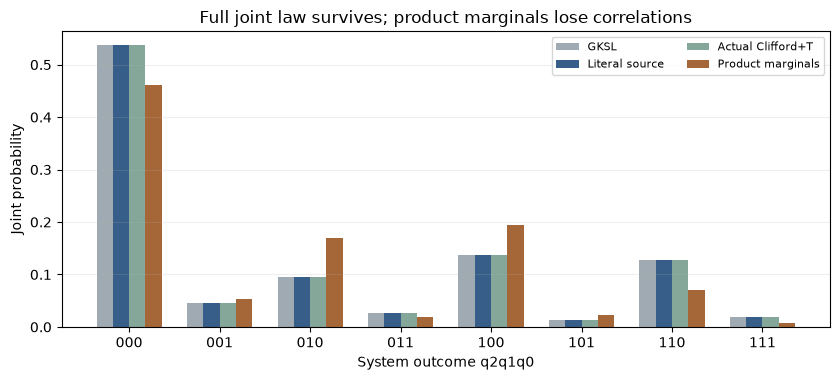

In [3]:
def local_marginal(state,q):
    # Independent explicit partial trace in little-endian three-system order.
    result=np.zeros((2,2),dtype=complex)
    rest=[j for j in range(3) if j!=q]
    for a in range(2):
        for b in range(2):
            for x in range(4):
                offset=sum(((x>>k)&1)<<j for k,j in enumerate(rest))
                result[a,b]+=state[offset|(a<<q),offset|(b<<q)]
    return result
marginals=[local_marginal(rho,q) for q in range(3)]
product=np.kron(marginals[2],np.kron(marginals[1],marginals[0]))
assert abs(np.trace(observable@product).real-fresh["mean"])<guard
assert np.linalg.norm(rho-product,ord="nuc")>.7
routed=prepared["routed_instrument_check"]
actual=prepared["clifford_t_instrument_check"]
routed_rho=density(routed["reduced_before_output"])
actual_rho=density(actual["reduced_before_output"])
assert np.linalg.norm(rho-routed_rho,ord="nuc")<guard
assert np.max(np.abs(fresh["joint_probabilities"]-routed["joint_probabilities"]))<guard
realization=prepared["error_contract"]["realization_Z0_bias_upper_proposal"]
assert np.linalg.norm(rho-actual_rho,ord="nuc")<=realization+guard
assert np.sum(np.abs(fresh["joint_probabilities"]-actual["joint_probabilities"]))<=realization+guard
for check in (routed,actual):
    assert check["outcome_clbits"]==[0,1,2]
    assert len(check["outcome_wires"])==len(set(check["outcome_wires"]))==3
    assert all(0<=q<6 for q in check["outcome_wires"])
    assert check["score_values"]==list(lp.score_values())
    assert len(check["joint_probabilities"])==8
    assert np.max(np.abs(np.diag(density(check["reduced_before_output"])).real-check["joint_probabilities"]))<guard
    assert abs(sum(check["joint_probabilities"])-1)<guard
    assert abs(np.dot(lp.score_values(),check["joint_probabilities"])-check["mean"])<guard
    assert check["simulation"]["trajectory_branch_pruning"] is False
    assert check["simulation"]["reset_history_measured_outputs"] is False
witnesses={"Z0":observable,"Z0 Z1":lw.on_wire(lw.Z,0,3)@lw.on_wire(lw.Z,1,3),
           "Z1 Z2":lw.on_wire(lw.Z,1,3)@lw.on_wire(lw.Z,2,3)}
table(pd.DataFrame([{"observable":name,"literal_source":float(np.trace(op@rho).real),
                    "product_of_source_marginals":float(np.trace(op@product).real),
                    "GKSL_reference":float(np.trace(op@reference).real)} for name,op in witnesses.items()]))
print("Product-marginal full-state trace-norm discrepancy:",np.linalg.norm(rho-product,ord="nuc"))
fig,ax=plt.subplots(figsize=(8.5,3.9))
x=np.arange(8)
for offset,law,label,color in ((-.27,np.diag(reference).real,"GKSL", "#a0aab2"),
                             (-.09,fresh["joint_probabilities"],"Literal source","#365e88"),
                             (.09,actual["joint_probabilities"],"Actual Clifford+T","#85a79a"),
                             (.27,np.diag(product).real,"Product marginals","#a56737")):
    ax.bar(x+offset,law,width=.18,label=label,color=color)
ax.set(xticks=x,xticklabels=[f"{i:03b}" for i in range(8)],xlabel="System outcome q2q1q0",ylabel="Joint probability",title="Full joint law survives; product marginals lose correlations")
ax.legend(fontsize=8,ncol=2)
ax.grid(axis="y",alpha=.2)
fig.tight_layout()
plt.show()

## Actual complete circuits and all trials

Every fresh-input trial keeps 268/268/134 environment initializations, including 267/267/133 reuse discards, and all six system/environment readouts. The physical model also reserves 17 workspace/bridge startup initializations per trial, giving 23 total reserved logical patches.

Full-unitary level0 lowering allocates every one of the 2,680 rotations. Seed7 SABRE routes the entire schedule on a bidirectional line; actual Clifford+T sequences replace its remaining rotations. Cached synthesis targets do not remove repeated quantum gate occurrences. Compiler barriers remain in instruction caps and have no extra cost in the serialized model. The following population is a calculated multiplication of actual complete-trial counts; the 15,756 trials have not run on hardware.

primitive,per_complete_trial,all_15756_trials
h,281671,4438008276
t,274432,4323950592
s,142845,2250665820
cx,5524,87036144
x,1072,16890432
reset,673,10603788
measure,6,94536


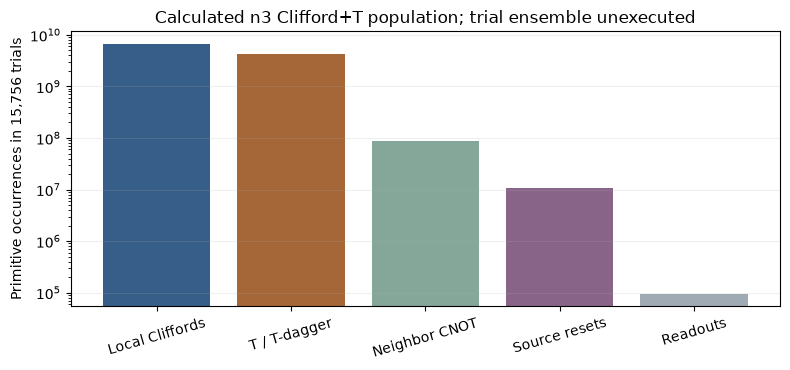

In [4]:
w=prepared["complete_workload"]
counts=w["primitive_counts_per_complete_trial"]
synthesis=prepared["actual_synthesis"]
assert w["complete_trials"]==w["complete_attempts"]==15756
assert w["algorithm_retry_cap"]==1 and w["postselection"]=="none"
assert w["whole_workload_executed"] is False
assert w["reset_per_trial"]==counts["reset"]==673
assert w["readout_per_trial"]==counts["measure"]==6
assert w["source_resets_all_trials"]==10603788 and w["source_readouts_all_trials"]==94536
assert w["environment_initializations_per_trial"]==[268,268,134]
assert w["discard_resets_before_environment_reuse_per_trial"]==[267,267,133]
assert w["source_reuse_resets_per_trial"]==667
assert w["workspace_startup_initializations_per_trial"]==17 and w["reserved_logical_patches"]==23
assert w["workspace_startup_initializations_all_trials"]==17*15756
assert w["logical_startup_initializations_all_trials"]==23*15756
assert w["data_output_clbits"]==[0,1,2] and w["ignored_environment_readout_clbits"]==[3,4,5]
assert w["unobserved_reset_histories_claimed_as_outputs"] is False
assert synthesis["rotation_occurrences"]==2680
assert synthesis["routed_counts"]["cx"]==5524 and synthesis["routed_counts"]["barrier"]==1358
assert sum(synthesis["routed_counts"].values())==10245
assert synthesis["clifford_t_counts"]["reset"]==673 and synthesis["clifford_t_counts"]["measure"]==6
assert set(counts)<=ir.CLIFFORD_T|{"reset","measure"}
for name,count in counts.items():
    assert w["primitive_counts_all_trials"][name]==count*15756
    assert synthesis["clifford_t_counts"][name]==count
table(pd.DataFrame([{"primitive":name,"per_complete_trial":count,"all_15756_trials":count*15756} for name,count in counts.items()]))
groups={"Local Cliffords":sum(counts.get(g,0) for g in ("h","x","y","z","s","sdg")),
        "T / T-dagger":sum(counts.get(g,0) for g in ("t","tdg")),
        "Neighbor CNOT":counts.get("cx",0),"Source resets":counts["reset"],"Readouts":counts["measure"]}
fig,ax=plt.subplots(figsize=(8,3.8))
ax.bar(groups.keys(),[v*15756 for v in groups.values()],color=["#365e88","#a56737","#85a79a","#876488","#a0aab2"])
ax.set(yscale="log",ylabel="Primitive occurrences in 15,756 trials",title="Calculated n3 Clifford+T population; trial ensemble unexecuted")
ax.tick_params(axis="x",rotation=16)
ax.grid(axis="y",alpha=.2)
fig.tight_layout()
plt.show()

## Two frozen physical profiles

The saved reports retain $p=10^{-3}$ and $10^{-4}$ with controller failure $10^{-15}$ per decision. These are the same frozen physical assumptions as the earlier workload. Gates and initialization take 100 ns, readout 500 ns, code cycles 1,000 ns and controller reaction 10,000 ns. Startup, resets, ignored readouts, trial dispatch, active/idle exposure, neighboring transport, injection/correction and complete factory retries are included in the serialized model.

Both recorded profiles have conditional feasible points at the unchanged controller setting. Their all-trial controller contribution is about 0.000692985, within the physical case allowance $1/1200$. The notebook verifies the saved physical component sums, readiness bounds, complete trial population and factory retries. These are additive engineering-model calculations rather than measured hardware failure rates. A rejected or missing feasible point would retain its explicit status without zero qubits/time or a different controller scenario.


physical_error,status,distance,peak_physical_qubits,all_trial_hours,controller_model_contribution,physical_fault_model,factory_readiness_model,physical_budget,Pareto_points
0.001000000,computed_conditional_instrument_surface_code_model,35,937967,14055.909791781,0.000692985,0.000811337,0.000043240,0.000833333,3
0.000100000,computed_conditional_instrument_surface_code_model,17,209451,7840.348828221,0.000692985,0.000758297,0.000043240,0.000833333,3


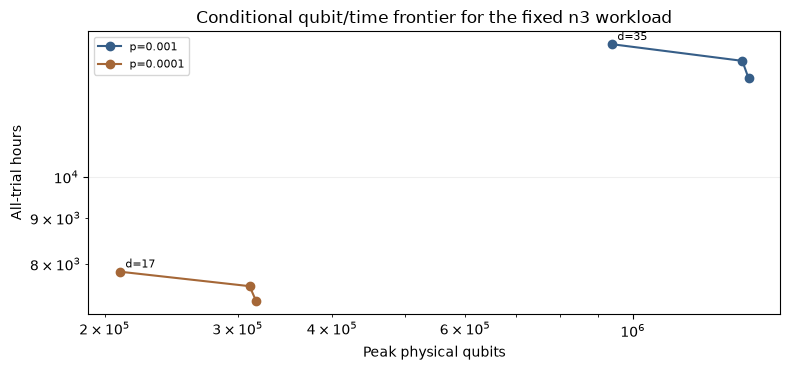

In [5]:
rows=[]
for report,frozen in zip(profiles,lp.fixed_profiles()):
    assert report["profile"]==asdict(frozen)
    assert report["profile"]["controller_failure_per_decision"]==1e-15
    assert report["complete_algorithm_attempts"]==15756
    assert report["physical_failure_budget"]<=float(Fraction(1,1200))
    best=point(report)
    diagnostic=report.get("controller_model_diagnostic",{})
    if best:
        assert report["status"]=="computed_conditional_instrument_surface_code_model"
        assert len(report["all_feasible_points"])==report["feasible_candidate_count"]
        for value in report["all_feasible_points"]:
            components=value["failure_components_all_attempts"]
            supply=value["factory_supply"]
            assert math.isclose(sum(components.values()),value["full_physical_failure_model"],rel_tol=1e-10,abs_tol=1e-13)
            assert value["full_physical_failure_model"]<=report["physical_failure_budget"]
            assert supply["availability_failure_union_bound"]<=report["factory_availability_budget"]
            assert value["reserved_logical_patches"]==23
            assert value["data_workspace_physical_qubits"]==23*(2*value["data_code_distance"]**2-1)
            assert value["peak_physical_qubits"]==value["data_workspace_physical_qubits"]+value["factory_physical_qubits"]
            assert value["worst_case_runtime_all_attempts_ns"]==value["runtime_per_complete_attempt_ns"]*15756
            ledger=value["macro_ledger_per_complete_attempt"]
            assert sum(row["count"]*row["time_ns"] for row in ledger)==value["runtime_per_complete_attempt_ns"]
            assert supply["states_all_complete_attempts"]==(counts.get("t",0)+counts.get("tdg",0))*15756
            assert supply["worst_case_pipeline_attempts"]==supply["states_all_complete_attempts"]*supply["full_pipeline_retry_cap_per_state"]
            assert math.isclose(supply["availability_failure_union_bound"],supply["states_all_complete_attempts"]*.01**supply["full_pipeline_retry_cap_per_state"],rel_tol=1e-12)
            assert math.isclose(components["controller_scenario"],diagnostic["distance_independent_controller_model_contribution"],rel_tol=1e-14)
        assert diagnostic["budget_exceeded"] is False
    if report["status"]=="infeasible_declared_controller_model":
        assert diagnostic["budget_exceeded"] is True
        assert diagnostic["distance_independent_controller_model_contribution"]>report["physical_failure_budget"]
        assert not report["pareto_points"] and not report["all_feasible_points"]
        assert diagnostic["controller_decisions_all_trials"]==diagnostic["controller_decisions_per_trial"]*15756
        assert math.isclose(diagnostic["distance_independent_controller_model_contribution"],
                            diagnostic["controller_decisions_all_trials"]*1e-15,rel_tol=1e-14)
    rows.append({"physical_error":report["profile"]["physical_error_rate"],"status":report["status"],
                 "distance":best["data_code_distance"] if best else None,
                 "peak_physical_qubits":best["peak_physical_qubits"] if best else None,
                 "all_trial_hours":best["worst_case_runtime_all_attempts_ns"]/3.6e12 if best else None,
                 "controller_model_contribution":diagnostic.get("distance_independent_controller_model_contribution"),
                 "physical_fault_model":best["full_physical_failure_model"] if best else None,
                 "factory_readiness_model":best["factory_supply"]["availability_failure_union_bound"] if best else None,
                 "physical_budget":report["physical_failure_budget"],"Pareto_points":len(report.get("pareto_points",[]))})
table(pd.DataFrame(rows))
fig,ax=plt.subplots(figsize=(8,3.8))
if all(r["status"]=="infeasible_declared_controller_model" for r in profiles):
    values=[r["controller_model_diagnostic"]["distance_independent_controller_model_contribution"] for r in profiles]
    ax.bar(["p=0.001","p=0.0001"],values,color=["#365e88","#a56737"],width=.5,label="All-trial controller term")
    ax.axhline(float(Fraction(1,1200)),color="#555555",linestyle="--",label="Unchanged physical case budget")
    ax.set(ylabel="Additive engineering-model fault contribution",title="Both frozen n3 profiles reject the controller budget")
    ax.legend(fontsize=8)
else:
    plotted=False
    for report,color in zip(profiles,("#365e88","#a56737")):
        points=report.get("pareto_points",[])
        if points:
            plotted=True
            ax.plot([p["peak_physical_qubits"] for p in points],[p["worst_case_runtime_all_attempts_ns"]/3.6e12 for p in points],"o-",color=color,label=f"p={report['profile']['physical_error_rate']:g}")
            value=min(points,key=lambda p:p["peak_physical_qubits"])
            ax.annotate(f"d={value['data_code_distance']}",(value["peak_physical_qubits"],value["worst_case_runtime_all_attempts_ns"]/3.6e12),xytext=(4,3),textcoords="offset points",fontsize=8)
    if plotted:
        ax.set(xscale="log",yscale="log",xlabel="Peak physical qubits",ylabel="All-trial hours")
        ax.legend(fontsize=8)
    else:
        ax.text(.5,.5,"No feasible model point; explicit report statuses retained",ha="center",va="center",transform=ax.transAxes)
    ax.set(title="Conditional qubit/time frontier for the fixed n3 workload")
ax.grid(axis="y",alpha=.2)
fig.tight_layout()
plt.show()

## Separate accuracy and family failure allocations

The retained absolute-error target is 0.05: 0.01 splitting allowance, 0.01 realization allowance and 0.03 statistics. The uniform splitting statement concerns exact decimal inputs and exact substeps. The saved guarded numerical synthesis sum plus separate $10^{-7}$ representation and $10^{-7}$ SDK/control/routing reserves give a **conditional** coherent premise $\eta$; ideal reset/CPTP contraction gives local mean change at most $2\eta$. Neither reserve is inferred from density agreement and deterministic bias is not multiplied by trials.

Across n=2,3,4, statistics receives 0.005 family failure and physical faults/readiness receive 0.0025 each. Every case keeps $1/600$, $1/1200$, $1/1200$ respectively. The prior n2 result is preserved; n4's allocation is not reassigned. Numerical realization evidence and physical-model infeasibility do not supply a full-family hardware-confidence certificate.

stage,absolute_Z0_error,scope
Uniform splitting bound,0.009865616,exact-substep source
Realization proposal,0.000017646,numerical synthesis + two conditional reserves
Statistics allowance,0.030000000,"15,756 complete independent scores"


guarded_synthesis_error,representation_reserve,SDK_reserve,exact_H_angle_component_upper,aggregate_absolute_error_proposal
0.000008623,0.000000100,0.000000100,0.000000000,0.039883262


systems,steps,complete_trials,status,physical_status
2,69,15756,preserved_prior_n2_result,prior_result_preserved
3,134,15756,implemented_six_wire_density_slice,computed_conditional_instrument_surface_code_model
4,211,15756,ensemble_branch_cap_exceeded,unimplemented_reserved_allocation


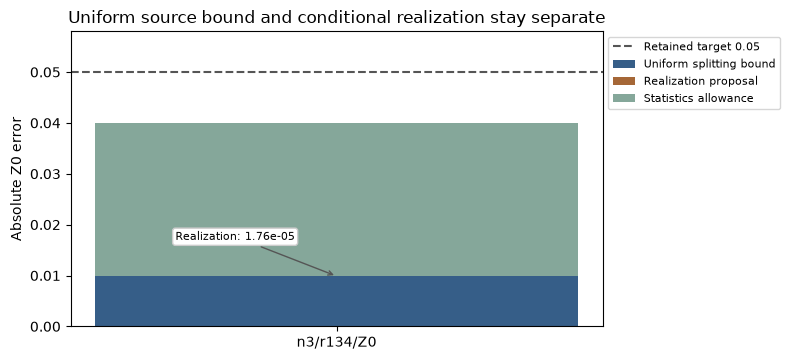

In [6]:
c=prepared["error_contract"]
representation=prepared["representation_check"]
assert fraction(c["splitting_bias_exact"])==lw.uniform_split_bound(task,134)
assert fraction(c["whole_realization_error_exact"])*2<=Fraction(1,100)
assert c["absolute_Z0_error_upper_proposal"]<=.05
assert c["representation_norm_reserve_scenario"]==c["SDK_control_routing_norm_reserve_scenario"]==1e-7
assert c["guarded_actual_synthesis_error"]==synthesis["guarded_numerical_operator_error_upper_estimate"]
assert c["reserve_is_inferred_from_density_agreement"] is False
assert c["coherent_error_is_stochastic_failure"] is False
assert c["full_representation_certificate"] is False
assert c["formal_synthesis_certificate"] is False and c["hardware_confidence_certificate"] is False
assert representation["representation_reserve_is_certified"] is False
allocations=prepared["family_allocations"]
assert allocations==results["family_allocations"]
assert allocations["declared_family"]==[2,3,4]
assert allocations["implemented_physical_cases"]==[2,3] and allocations["new_physical_cases"]==[3]
assert allocations["unused_cases_reallocated"] is False and allocations["family_physical_confidence_implemented"] is False
assert fraction(allocations["statistics_family_failure_exact"])==Fraction(1,200)
assert fraction(allocations["physical_family_failure_exact"])==Fraction(1,400)
assert fraction(allocations["factory_family_failure_exact"])==Fraction(1,400)
assert fraction(allocations["total_conditional_family_failure_exact"])==Fraction(1,100)
for n,allocation in allocations["case_allocations"].items():
    assert fraction(allocation["statistical_failure_exact"])==Fraction(1,600)
    assert fraction(allocation["physical_failure_exact"])==Fraction(1,1200)
    assert fraction(allocation["factory_availability_failure_exact"])==Fraction(1,1200)
assert w["deterministic_bias_multiplied_by_trials"] is False
budget=[{"stage":"Uniform splitting bound","absolute_Z0_error":c["splitting_bias_upper"],"scope":"exact-substep source"},
        {"stage":"Realization proposal","absolute_Z0_error":c["realization_Z0_bias_upper_proposal"],"scope":"numerical synthesis + two conditional reserves"},
        {"stage":"Statistics allowance","absolute_Z0_error":c["statistical_absolute_error"],"scope":"15,756 complete independent scores"}]
table(pd.DataFrame(budget))
table(pd.DataFrame([{"guarded_synthesis_error":c["guarded_actual_synthesis_error"],
                    "representation_reserve":c["representation_norm_reserve_scenario"],
                    "SDK_reserve":c["SDK_control_routing_norm_reserve_scenario"],
                    "exact_H_angle_component_upper":representation["Hamiltonian_angle_coherent_error_component_upper"],
                    "aggregate_absolute_error_proposal":c["absolute_Z0_error_upper_proposal"]}]))
table(pd.DataFrame([{"systems":r["n_system"],"steps":r["selected_steps"],"complete_trials":r["complete_trials"],
                    "status":r["status"],"physical_status":(", ".join(dict.fromkeys(p["status"] for p in profiles)) if r["n_system"]==3 else r.get("physical_status",r["status"]))} for r in family_records]))
fig,ax=plt.subplots(figsize=(8,3.7))
bottom=0
for row,color in zip(budget,("#365e88","#a56737","#85a79a")):
    ax.bar(["n3/r134/Z0"],[row["absolute_Z0_error"]],bottom=bottom,label=row["stage"],color=color,width=.45)
    bottom+=row["absolute_Z0_error"]
ax.axhline(.05,color="#555555",linestyle="--",label="Retained target 0.05")
ax.annotate(f"Realization: {c['realization_Z0_bias_upper_proposal']:.3g}",
            xy=(0,c["splitting_bias_upper"]+c["realization_Z0_bias_upper_proposal"]/2),
            xytext=(-.15,.017),arrowprops={"arrowstyle":"->","color":"#555555"},
            bbox={"boxstyle":"round,pad=.25","fc":"white","ec":"#cccccc"},fontsize=8)
ax.set(ylabel="Absolute Z0 error",ylim=(0,.058),title="Uniform source bound and conditional realization stay separate")
ax.legend(fontsize=8,loc="upper left",bbox_to_anchor=(1,1))
fig.tight_layout()
plt.show()

## Reproduction, provenance and limits

In the checkout, the coordinator generates the bundle with `PYTHONPATH=src python scripts/generate_simulation_lindblad_three.py`. This notebook loads that evidence and performs one bounded source check. To run a downloaded copy, place the copied Python modules, manifest/results/inventory/CSV, QASM files, lock, license and references beside the notebook and use the recorded Python 3.12 environment. No Git checkout or native synthesis run is needed for its numerical checks.

The run caps cover one new physical case, one prepared whole-circuit synthesis stage, six density wires, 20,000 source instructions and 1,000,000 compiled/validation instructions. The 64 KiB density-array size excludes temporary arrays, caches and process overhead. Stage timeouts, native rotation attempts, query counts and artifact storage are recorded; candidates are not silently truncated. The n4 source remains outside the density width and ensemble branch caps. The earlier n2 data/source are preserved rather than regenerated.

Saved QASM and sequence hashes identify native synthesis, whose backend has no seed API; compiler seed7 is fixed. Measured-instrument QASM omits overall phase and is not a controlled-oracle specification; coherent reuse of a unitary segment requires its phase convention and recorded in-memory phase. Representation/SDK reserves, physical interfaces and hardware calibration retain distinct scope. Offline preprocessing/report time, layout certification and decoder throughput are outside quantum runtime. No full representation, formal synthesis, hardware-confidence or advantage claim is supplied.

In [7]:
assert manifest["frozen_before"]==manifest["frozen_after"]
assert manifest["private_cache_distributed"] is False
assert manifest["whole_family_physical_completed"] is False
assert manifest["synthesis_seed"] is None and manifest["transpiler_seed"]==7
assert prepared["hardware_execution"] is False and prepared["formal_confidence_certificate"] is False
assert prepared["joint_system_correlations_preserved"] is True
assert prepared["unobserved_reset_histories_are_measured_outputs"] is False
assert prepared["output_clbits"]==[0,1,2] and prepared["score_values"]==list(lp.score_values())
assert synthesis["actual_synthesis_sequences_generated"] is True
assert synthesis["preserve_full_unitary"] is True and synthesis["transpiler_qubits_initially_zero"] is False
assert synthesis["formal_interval_certificate"] is False
phases=prepared["qasm_export"]["in_memory_global_phase_radians"]
assert set(phases)==set(prepared["qasm_sha256"]) and all(math.isfinite(v) for v in phases.values())
assert phases["clifford-t-trial.qasm"]==synthesis["compiled_global_phase"]
assert synthesis["native_synthesis_backend"]["qiskit_262_cargo_lock_version"]=="0.2.2"
assert synthesis["native_synthesis_backend"]["upstream_tag_commit"]=="0e94e5638c42624f4ec358f5eab079942462d2bf"
for record in family_records:
    if record["n_system"]==2:
        assert record["regenerated"] is False and record["source_or_synthesis_rerun"] is False
    if record["n_system"]==4:
        assert record["synthesis_performed"] is False and record["physical_estimation_performed"] is False
        assert record["family_allocation_reallocated"] is False
        assert record["rejection_reproduced"] is True and "branch cap" in record["reason"]
        assert record["density_checker_status"]=="density_width_cap_exceeded"
        assert record["density_width_rejection_reproduced"] is True and "width" in record["density_checker_reason"]
        assert record["density_required_wires"]==8 and record["density_supported_wires"]==6
        assert record["density_checker_limits"]==prepared["checker_limits"]
caps=prepared["run_caps"]
assert caps==manifest["run_caps"]
assert caps["physical_cases"]==caps["prepared_synthesis_stages"]==1 and caps["physical_profiles"]==2
assert caps["density_wires"]==6 and caps["density_matrix_entries"]==4096 and caps["density_matrix_bytes"]==65536
assert caps["native_rotation_synthesis_attempts_upper_bound"]==10720
assert caps["factory_queries_per_profile"]==caps["surface_code_queries_per_profile"]==24
assert caps["factory_candidates_per_query"]==1000 and caps["factory_candidates_per_profile"]==24000
assert caps["managed_json_qasm_bytes"]==32*1024**2
observed_attempts=synthesis.get("native_rotation_synthesis_attempts")
if observed_attempts is not None:
    assert 0<=observed_attempts<=caps["native_rotation_synthesis_attempts_upper_bound"]
    print("Observed native rotation-synthesis attempts:",observed_attempts)
print("Actual unique rotation targets:",synthesis["unique_rotation_targets"])
print("Recorded package versions:",manifest["packages"])
table(pd.DataFrame([{"cap":name.replace("_"," "),"value":value} for name,value in caps.items() if isinstance(value,int) and not isinstance(value,bool)]))
inventory=pd.read_csv(asset_dir/"artifact-inventory.csv")
inventory_record=json.loads((asset_dir/"artifact-inventory.json").read_text())
assert len(inventory)==inventory_record["payload_files"]==manifest["artifact_inventory"]["payload_files"]
assert int(inventory["bytes"].sum())==inventory_record["payload_bytes"]==manifest["artifact_inventory"]["payload_bytes"]
assert inventory_record["originals_preserved"] is True
assert inventory_record["baseline_local_inventory"]["preserved_n2_files"]==26
assert inventory_record["baseline_local_inventory"]["preserved_n2_total_bytes"]==3505619
for row in inventory.to_dict("records"):
    raw=(asset_dir/row["file"]).read_bytes()
    assert len(raw)==row["bytes"] and hashlib.sha256(raw).hexdigest()==row["sha256"], row["file"]
table(inventory.groupby("category",sort=False).agg(files=("file","count"),bytes=("bytes","sum")).reset_index())
print("Managed local payload:",inventory_record["payload_files"],"files;",inventory_record["payload_bytes"],"bytes. This excludes recursive metadata and is not public hosting occupancy.")
print("Saved identities, complete trial counts, joint correlations, unused n4 shares and unexecuted-population labels verified.")

Observed native rotation-synthesis attempts: 8
Actual unique rotation targets: 8
Recorded package versions: {'qiskit': '2.6.2', 'qdk': '1.34.0', 'numpy': '2.5.4', 'scipy': '1.18.1', 'matplotlib': '3.11.2'}


cap,value
physical cases,1
prepared synthesis stages,1
native rotation synthesis attempts upper bound,10720
physical profiles,2
source instructions,20000
routed and synthesized instructions,1000000
density validation instructions,1000000
density wires,6
density matrix entries,4096
density matrix bytes,65536


category,files,bytes
copied_license_or_primary_references,2,12000
result_or_documentation,4,1180830
new_original_source_snapshot,3,103158
actual_circuit_export,3,6041850
original_figure,5,255277
copied_frozen_source_dependency,4,109755
copied_environment_lock,1,1974


Managed local payload: 22 files; 7704844 bytes. This excludes recursive metadata and is not public hosting occupancy.
Saved identities, complete trial counts, joint correlations, unused n4 shares and unexecuted-population labels verified.
